# Aufgabe 10.2 – AI4I mit Jupyter erkunden

**Status: APPROVED (26.10.2026).** Initiale Implementierung und automatisierte Prüfung:
Codex. Die beiden abschließenden Markdown-Zellen wurden vom Studierenden verfasst;
ihre Freigabe wurde ausdrücklich bestätigt. Merge-Freigabe steht weiterhin aus.

Ziel: einen Datensatz laden, eine begrenzte deskriptive Übersicht erstellen und
Notebook-Zelltypen sowie HTML/PDF-Exporte verwenden.

Quelle der Aufgabe: [Industrial Data Science, Exercise 10.2](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/6_self_study_session1.html).
Abruf: 26.10.2026. Ausführung aus dem Projektstamm oder aus diesem Notebook-Ordner.
Vorher: `uv sync --locked` und `uv run python scripts/download_ai4i.py`.
Danach ist die Notebookausführung ohne Netzwerkzugriff möglich.

## Datenherkunft und Umfang

[AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset),
UCI Machine Learning Repository (2020), [DOI 10.24432/C5HS5C](https://doi.org/10.24432/C5HS5C),
[CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
Der Datensatz ist **synthetisch** und enthält laut Anbieter 10.000 Zeilen.
Originaldaten, Prüfsumme und Downloadweg sind in `data/raw/README.md` dokumentiert.

Wir behalten ausschließlich `UDI`, `Torque [Nm]`, `Rotational speed [rpm]`
und `Air temperature [K]`. UDI dient als Zeilenkennung, nicht als Zeitstempel.
Wir schätzen keine Modelle und treffen keine kausalen Aussagen.

In [1]:
from pathlib import Path
import os
import sys

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.environ.setdefault("MPLCONFIGDIR", str(root / ".tools/matplotlib"))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image
from sessions.ch10.ai4i_data import COLUMNS, DATA_PATH, verify_file, validate_data

output_dir = root / "outputs/ch10/exercise_10_2"
output_dir.mkdir(parents=True, exist_ok=True)
print(f"Python {sys.version.split()[0]}; pandas {pd.__version__}; Matplotlib {matplotlib.__version__}")

Python 3.12.15; pandas 2.3.3; Matplotlib 3.11.2


## Laden und Datenqualität

Der Download erfolgt ausdrücklich vor der Analyse. Zuerst prüfen wir die exakten
Rohbytes mittels SHA256; dann liest pandas nur die vier geforderten Spalten.
Ihre Reihenfolge und Einheiten bleiben explizit. Fehlende Werte oder unerwartete
Kennungen führen zum Abbruch, nicht zu stiller Imputation.

In [2]:
digest = verify_file(DATA_PATH)
data = pd.read_csv(DATA_PATH, usecols=COLUMNS).loc[:, COLUMNS]
validate_data(data)
assert isinstance(data, pd.DataFrame)
print(f"Form: {data.shape[0]} Zeilen × {data.shape[1]} Spalten")
print(f"SHA256: {digest}")
print("Fehlende Werte je Spalte:")
print(data.isna().sum().to_string())

Form: 10000 Zeilen × 4 Spalten
SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
Fehlende Werte je Spalte:
UDI                       0
Torque [Nm]               0
Rotational speed [rpm]    0
Air temperature [K]       0


## Die ersten zehn Zeilen

`head(10)` zeigt die ersten zehn Beobachtungen in Originalreihenfolge.
Kelvin, rpm und Nm bleiben in den Spaltennamen sichtbar.

In [3]:
first_ten = data.head(10)
assert first_ten.shape == (10, 4)
display(first_ten)

,UDI,Torque [Nm],Rotational speed [rpm],Air temperature [K]
0,1,42.8,1551,298.1
1,2,46.3,1408,298.2
2,3,49.4,1498,298.1
3,4,39.5,1433,298.2
4,5,40.0,1408,298.2
5,6,41.9,1425,298.1
6,7,42.4,1558,298.1
7,8,40.2,1527,298.1
8,9,28.6,1667,298.3
9,10,28.0,1741,298.5


## Grundstatistik

`describe()` zeigt Anzahl, Mittelwert, Standardabweichung, Minimum, Quartile und
Maximum. Die Statistik von UDI beschreibt nur die Nummerierung und ist keine
physikalische Kennzahl. Es werden keine Zeilen entfernt oder Werte verändert.

In [4]:
summary = data.describe()
assert (summary.loc["count"] == 10000).all()
display(summary)
summary.to_csv(output_dir / "summary_statistics.csv")

,UDI,Torque [Nm],Rotational speed [rpm],Air temperature [K]
count,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,39.986910,1538.776100,300.004930
std,2886.89568,9.968934,179.284096,2.000259
min,1.00000,3.800000,1168.000000,295.300000
25%,2500.75000,33.200000,1423.000000,298.300000
50%,5000.50000,40.100000,1503.000000,300.100000
75%,7500.25000,46.800000,1612.000000,301.500000
max,10000.00000,76.600000,2886.000000,304.500000


## Drehmoment über UDI

Die Linie verbindet alle Beobachtungen in ihrer UDI-Reihenfolge. Sie visualisiert
die vom Auftrag geforderte Zuordnung, beweist aber keinen zeitlichen Verlauf.
Bei 10.000 Punkten ist Überlagerung zu erwarten; die Grafik dient einer ersten
Übersicht. Eine physikalische Interpretation würde zusätzliche Prozesskenntnis
und Zeitangaben benötigen.

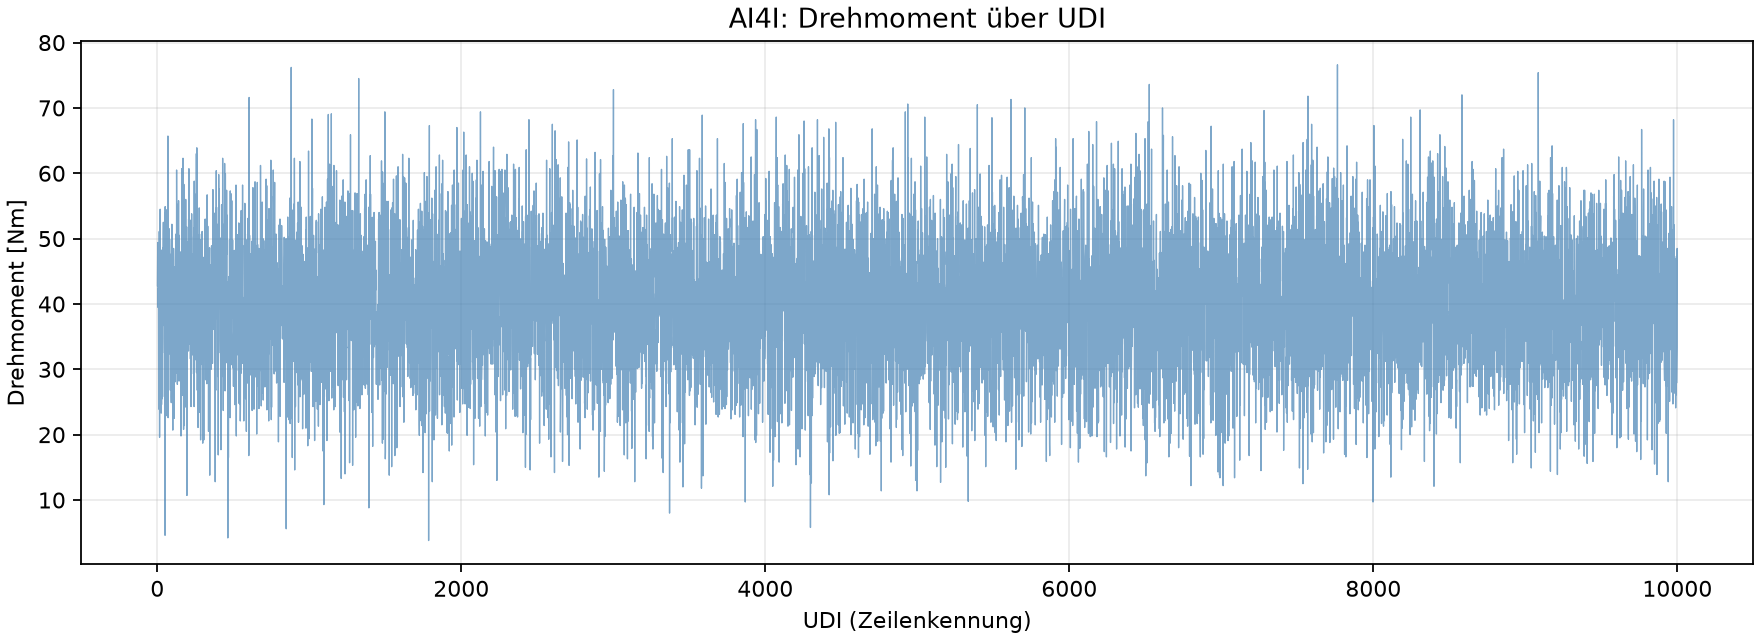

In [5]:
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(data["UDI"], data["Torque [Nm]"], linewidth=0.6, alpha=0.7, color="steelblue")
ax.set(title="AI4I: Drehmoment über UDI", xlabel="UDI (Zeilenkennung)", ylabel="Drehmoment [Nm]")
ax.grid(alpha=0.25)
plot_path = output_dir / "torque_over_udi.png"
fig.savefig(plot_path, dpi=160)
display(Image(filename=str(plot_path)))
plt.close(fig)

## Tatsächlich berechnete Zusammenfassung

Die folgenden Zahlen werden aus dem geladenen DataFrame berechnet, nicht von der
KI vorab eingesetzt. Es handelt sich um deskriptive Angaben zu synthetischen Daten.

In [6]:
display(Markdown(
    f"Geprüft wurden **{len(data):,} Zeilen** und **{len(data.columns)} Spalten**. "
    f"In diesen Spalten fehlen **{int(data.isna().sum().sum())} Werte**. "
    f"Das mittlere Drehmoment beträgt **{data['Torque [Nm]'].mean():.3f} Nm** "
    f"(Minimum {data['Torque [Nm]'].min():.1f}, Maximum {data['Torque [Nm]'].max():.1f} Nm). "
    "Die Ergebnisse erlauben weder eine Kausalitätsaussage noch den Nachweis realer Maschinendynamik."
))

Geprüft wurden **10,000 Zeilen** und **4 Spalten**. In diesen Spalten fehlen **0 Werte**. Das mittlere Drehmoment beträgt **39.987 Nm** (Minimum 3.8, Maximum 76.6 Nm). Die Ergebnisse erlauben weder eine Kausalitätsaussage noch den Nachweis realer Maschinendynamik.

## Zelltypen und Export

- **Code:** wird vom Python-Kernel ausgeführt; Reihenfolge und Zustand beeinflussen Ergebnisse.
- **Markdown:** enthält Erläuterungen, Links und Formatierung; kein Python-Code.
- **Raw:** enthält unverarbeiteten Text, wird nicht vom Kernel ausgeführt; ob er in
  einem Export erscheint, hängt von Exportformat und Raw-MIME-Einstellung ab.

Die nächste Zelle ist tatsächlich vom Typ Raw. Der Notebook-Export wird durch
`uv run python scripts/build_exercise_10_2.py` reproduziert: frischer Kernel,
gespeicherte Ausgaben, HTML mit eingebetteter Grafik und PDF über Chromium.
Der alternative nbconvert-PDF-Weg über LaTeX ist nicht erforderlich.

## Fragen für die studentische Prüfung

1. Kannst du erklären, weshalb wir Originaleinheiten beibehalten und UDI nicht als Zeit interpretieren?
2. Stimmen Auswahl der vier Spalten, erste zehn Zeilen, Statistik und Achsen mit dem Auftrag überein?
3. Kannst du den Unterschied zwischen Code, Markdown und Raw im Notebook nachvollziehen?
4. Sind HTML/PDF einschließlich Tabellen und Grafik lesbar, und lässt sich die Ausführung reproduzieren?

**Studentische Freigabe am 26.10.2026 ausdrücklich bestätigt. Kein Merge und keine automatische Abgabe.**

## Selbst erklären können – Aufgabe 10.2

**1. Warum Originaleinheiten beibehalten und UDI nicht als Zeit interpretieren?**

Die Originaleinheiten ermöglichen eine physikalisch sinnvolle Interpretation und verhindern Verwechslungen. UDI ist lediglich eine eindeutige Zeilenkennung und enthält keine Zeitinformation. Deshalb darf die Darstellung nicht als zeitlicher Verlauf interpretiert werden.

**2. Stimmen Spalten, Tabellen, Statistik und Achsen überein?**

Die vier Spalten UDI, Torque [Nm], Rotational speed [rpm] und Air temperature [K] sind vorhanden. Die ersten zehn Beobachtungen und die deskriptive Statistik werden angezeigt. Die Grafik stellt das Drehmoment über UDI mit korrekt beschrifteten Achsen dar.

**3. Unterschied zwischen Code, Markdown und Raw?**

Code-Zellen führen Python-Befehle aus und erzeugen Ergebnisse. Markdown-Zellen enthalten formatierte Texte und Erklärungen. Raw-Zellen enthalten unverarbeiteten Text, der nicht als Python-Code ausgeführt wird.

**4. Sind HTML/PDF lesbar und die Ergebnisse reproduzierbar?**

Die bereitgestellten Exporte enthalten Tabellen, statistische Kennzahlen und die Grafik. Die PDF-Darstellung ist lesbar. Laut Codex wurden alle sechs Code-Zellen erfolgreich ausgeführt und die automatisierten Prüfungen bestanden.

## Human Review – Aufgabe 10.2

**Status:** APPROVED  
**KI-Unterstützung:** Codex  
**Prüfung:** Studentischer Human Review

### Prüfergebnisse

1. Der AI4I-Datensatz enthält 10.000 Beobachtungen. Die vier ausgewählten Spalten und ihre Einheiten wurden kontrolliert.
2. Die Vorschau zeigt die ersten zehn Zeilen. Die deskriptive Statistik ist vollständig und nachvollziehbar.
3. Das durchschnittliche Drehmoment beträgt 39,987 Nm. Der kleinste Wert beträgt 3,8 Nm, der größte 76,6 Nm.
4. Die Drehmomentgrafik ist korrekt beschriftet und zeigt deutliche Schwankungen. UDI wird richtigerweise nicht als Zeitachse interpretiert.
5. Die Unterschiede zwischen Code-, Markdown- und Raw-Zellen sind nachvollziehbar.
6. Die HTML- und PDF-Exporte wurden auf Lesbarkeit und Vollständigkeit geprüft.
7. Codex meldet 13 erfolgreiche Tests und zwei bestandene GitHub-Actions-Läufe.

### Bewertung

Die Ergebnisse sind plausibel, die Dokumentation verständlich und die Aufgabenanforderungen nach Prüfung erfüllt.

Keine Korrekturen erforderlich.

**Human Review: Approved**